# ParticleSignal: Machine Learning-Based Classification of Signal and Background Events in High-Energy Physics

**Notebook 2 of the project: EDA, preprocessing, model training and evaluation**

The training data comes from `../training_data/train.csv` and the final evaluation uses `../testing_data/test.csv`. Both files were created by `split_data.py` (stratified 80/20 split, seed 42) from the Kaggle *Particle Physics Event Classification* dataset.

Each row is one simulated proton–proton collision event. The goal is to decide whether an event is **signal** (`s`, a Higgs boson decaying to two tau leptons, H → ττ) or **background** (`b`, other processes that leave a similar footprint in the detector, mainly Z → ττ, top-quark pairs and W bosons).

### Contents
1. Setup
2. Loading the training data
3. Exploratory data analysis (EDA)
4. Data preprocessing and feature engineering
5. Model training: Logistic Regression, Random Forest, XGBoost, LightGBM
6. Evaluation and comparison on the test set
7. Conclusions and limitations

## 1. Setup

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, log_loss, confusion_matrix)
import xgboost as xgb
import lightgbm as lgb
import sklearn

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

TRAIN_PATH = "../training_data/train.csv"
TEST_PATH  = "../testing_data/test.csv"
FIG_DIR    = "figures"
RESULT_DIR = "results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Size of the full Kaggle dataset (train + test). Needed later to rescale the
# physics weights of a subset back to the full luminosity when computing AMS.
N_TOTAL = 250_000

for lib in (np, pd, sklearn, xgb, lgb):
    print(f"{lib.__name__:<10} {lib.__version__}")

numpy      2.1.3
pandas     2.2.3
sklearn    1.6.1
xgboost    3.4.1
lightgbm   4.6.0


In [ ]:
# ---- Plot style used throughout the notebook ----
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"

C_BKG, C_SIG = "#2a78d6", "#eb6834"          # background = blue, signal = orange
MODEL_COLORS = {"Logistic Regression": "#1baf7a",
                "Random Forest":       "#6250d6",
                "XGBoost":             "#eda100",
                "LightGBM":            "#e34948"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "figure.dpi": 100, "font.family": "DejaVu Sans",
})

def save(fig, name):
    # Save every figure so it can be reused in the slides and the article.
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

## 2. Loading the training data

In [ ]:
train = pd.read_csv(TRAIN_PATH)
print("Training set shape:", train.shape)
train.head()

Training set shape: (200000, 33)


,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,...,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label
0,193497,157.494,9.783,109.143,10.403,1.113,103.076,3.275,3.270,0.495,...,2,49.326,1.337,-2.979,39.449,2.450,0.142,88.776,1.454848,b
1,197173,94.469,11.514,62.460,39.033,-999.000,-999.000,-999.000,2.868,2.958,...,1,36.087,2.463,0.897,-999.000,-999.000,-999.000,36.087,0.018636,s
2,153513,88.249,25.534,59.709,31.178,-999.000,-999.000,-999.000,3.323,4.152,...,1,35.288,0.344,1.043,-999.000,-999.000,-999.000,35.288,0.018636,s
3,208664,165.934,75.831,122.360,66.142,-999.000,-999.000,-999.000,2.938,22.413,...,1,88.008,0.074,2.262,-999.000,-999.000,-999.000,88.008,2.495801,b
4,321861,96.702,29.294,55.545,68.306,2.937,451.427,-2.156,2.716,3.334,...,2,101.636,1.434,2.257,97.969,-1.504,-1.614,199.605,0.309795,b


In [ ]:
print(train.dtypes.value_counts().to_string())
print("\nNaN values in the file:", train.isna().sum().sum())
print("Duplicate EventIds   :", train["EventId"].duplicated().sum())

float64    30
int64       2
str         1

NaN values in the file: 0
Duplicate EventIds   : 0


In [ ]:
ID_COL, WEIGHT_COL, LABEL_COL = "EventId", "Weight", "Label"
FEATURES = [c for c in train.columns if c not in (ID_COL, WEIGHT_COL, LABEL_COL)]
DER = [c for c in FEATURES if c.startswith("DER_")]
PRI = [c for c in FEATURES if c.startswith("PRI_")]
print(f"{len(FEATURES)} features: {len(DER)} derived (DER_*) + {len(PRI)} primary (PRI_*)")

train[FEATURES].describe().T.round(3)

30 features: 13 derived (DER_*) + 17 primary (PRI_*)


,count,mean,std,min,25%,50%,75%,max
DER_mass_MMC,200000.0,-48.615,405.935,-999.000,78.177,105.020,130.633,1192.026
DER_mass_transverse_met_lep,200000.0,49.202,35.292,0.000,19.173,46.498,73.622,690.075
DER_mass_vis,200000.0,81.179,40.701,6.329,59.385,73.761,92.270,1349.351
DER_pt_h,200000.0,57.923,63.801,0.000,14.108,38.442,79.184,2834.999
DER_deltaeta_jet_jet,200000.0,-708.548,454.421,-999.000,-999.000,-999.000,0.487,9.000
DER_mass_jet_jet,200000.0,-601.464,657.860,-999.000,-999.000,-999.000,83.380,4974.979
DER_prodeta_jet_jet,200000.0,-709.487,452.962,-999.000,-999.000,-999.000,-4.608,16.690
DER_deltar_tau_lep,200000.0,2.374,0.782,0.208,1.811,2.492,2.962,5.684
DER_pt_tot,200000.0,18.885,22.315,0.000,2.842,12.346,27.576,2834.999
DER_sum_pt,200000.0,158.380,115.458,46.104,77.577,120.618,200.489,1675.449


**Column groups**

* `PRI_*` (**primary**) quantities are measured directly for the reconstructed objects: the hadronic tau (`tau`), the lepton (`lep`, electron or muon), up to two jets and the missing transverse energy (`met`, carried away by neutrinos). For each object we get transverse momentum $p_T$, pseudorapidity $\eta$ and azimuthal angle $\phi$.
* `DER_*` (**derived**) quantities are computed by physicists from the primary ones, for example invariant masses and the Missing Mass Calculator estimate `DER_mass_MMC` of the Higgs mass.
* `Weight` is the event weight from the simulation (cross-section × luminosity / number generated). It is **not** a feature and is only used for training weights and for the physics metric (AMS).
* `EventId` is just an identifier and is dropped.

From `describe()` the minimum of many columns is exactly **-999.0**. That is not a physical value; the dataset uses it to say *"this quantity cannot be computed for this event"*. Section 3.2 looks at this in detail.

## 3. Exploratory data analysis
### 3.1 Class balance: event counts vs physics weights

,events,events_%,sum_of_weights,weight_%
Label,,,,
b,131466,65.73,328922.56,99.832
s,68534,34.27,553.06,0.168


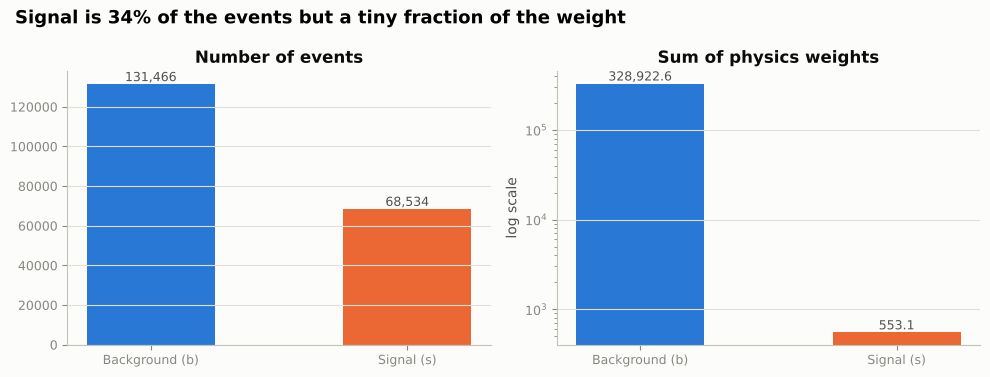

In [ ]:
counts  = train[LABEL_COL].value_counts().reindex(["b", "s"])
wsum    = train.groupby(LABEL_COL)[WEIGHT_COL].sum().reindex(["b", "s"])
summary = pd.DataFrame({"events": counts,
                        "events_%": (100 * counts / counts.sum()).round(2),
                        "sum_of_weights": wsum.round(2),
                        "weight_%": (100 * wsum / wsum.sum()).round(3)})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
names = ["Background (b)", "Signal (s)"]
for ax, vals, title, fmt in [(axes[0], counts.values, "Number of events", "{:,.0f}"),
                             (axes[1], wsum.values, "Sum of physics weights", "{:,.1f}")]:
    bars = ax.bar(names, vals, color=[C_BKG, C_SIG], width=0.5)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                ha="center", va="bottom", color=INK2, fontsize=9)
    ax.set_title(title); ax.grid(axis="x", visible=False)
axes[1].set_yscale("log"); axes[1].set_ylabel("log scale")
fig.suptitle("Signal is 34% of the events but a tiny fraction of the weight",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(); save(fig, "01_class_balance"); plt.show()

**Observation.** By event count the data is only mildly imbalanced: 65.7% background and 34.3% signal. By physics weight it is extremely imbalanced: signal is just **0.17%** of the total weight (553 vs 328,923). The simulation deliberately generated many more signal events than nature would produce, and the weights correct for that. This matters for training: if I used the raw weights as `sample_weight`, the models would effectively never see signal (Section 4.3).

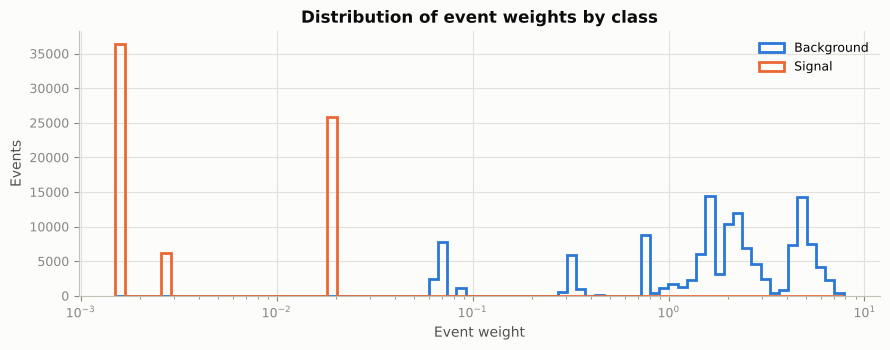

          count    mean     std     min     25%     50%     75%     max
Label                                                                  
b      131466.0  2.5020  1.7945  0.0641  1.3402  2.0802  4.3582  7.8225
s       68534.0  0.0081  0.0082  0.0015  0.0015  0.0015  0.0186  0.0186


In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(np.log10(train[WEIGHT_COL].min()), np.log10(train[WEIGHT_COL].max()), 80)
for lab, col, name in [("b", C_BKG, "Background"), ("s", C_SIG, "Signal")]:
    ax.hist(train.loc[train[LABEL_COL] == lab, WEIGHT_COL], bins=bins,
            histtype="step", color=col, lw=2, label=name)
ax.set_xscale("log"); ax.set_xlabel("Event weight"); ax.set_ylabel("Events")
ax.set_title("Distribution of event weights by class"); ax.legend()
fig.tight_layout(); save(fig, "02_weight_distribution"); plt.show()

print(train.groupby(LABEL_COL)[WEIGHT_COL].describe().round(4))

**Observation.** The two classes live in completely separate weight ranges. Every signal event has a weight between 0.0015 and 0.019 (only a handful of distinct values, one per simulated sample), while background weights range from 0.06 to 7.8. Because of this, the weight on its own would perfectly identify the class. That is why `Weight` must **never** be used as an input feature: it would be target leakage, and it is not available for real collision data anyway.

### 3.2 Missing values (the -999 placeholder)

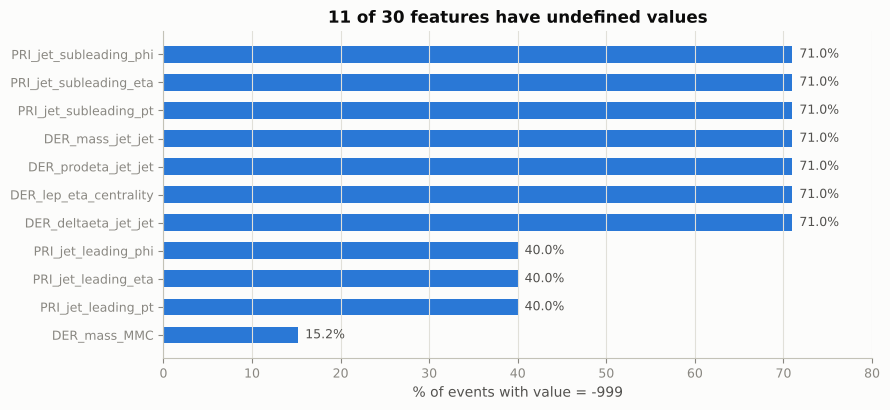

In [ ]:
miss = (train[FEATURES] == -999.0).mean().sort_values(ascending=True)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(miss.index, 100 * miss.values, color=C_BKG, height=0.6)
for i, v in enumerate(miss.values):
    ax.text(100 * v + 0.8, i, f"{100*v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_xlabel("% of events with value = -999"); ax.set_xlim(0, 80)
ax.set_title(f"{len(miss)} of {len(FEATURES)} features have undefined values")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "03_missing_fraction"); plt.show()

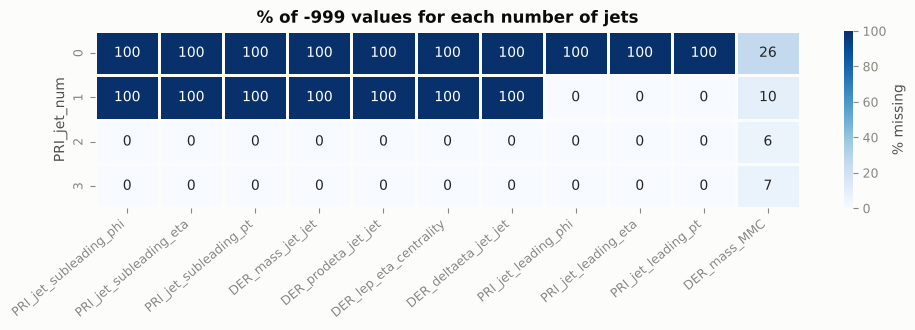

In [ ]:
# Is the missingness random, or does it follow the number of jets in the event?
miss_by_jet = (train[FEATURES] == -999.0).groupby(train["PRI_jet_num"]).mean()[miss.index[::-1]]

fig, ax = plt.subplots(figsize=(10, 3.4))
sns.heatmap(100 * miss_by_jet, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% missing"}, linewidths=1, linecolor=SURFACE, ax=ax)
ax.grid(False)
ax.set_ylabel("PRI_jet_num"); ax.set_xlabel("")
ax.set_title("% of -999 values for each number of jets")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout(); save(fig, "04_missing_by_jets"); plt.show()

**Observation.** The missing values are **not random**. They follow the physics of the event:

* With `PRI_jet_num = 0` every jet variable is undefined (100%).
* With `PRI_jet_num = 1` the leading-jet variables exist, but all subleading-jet and dijet variables (`DER_deltaeta_jet_jet`, `DER_mass_jet_jet`, `DER_prodeta_jet_jet`, `DER_lep_eta_centrality`) are undefined. That is why these columns are all missing in exactly **71.0%** of events (= events with 0 or 1 jet), and the leading-jet columns in **40.0%** (= events with 0 jets).
* With 2 or 3 jets, nothing jet-related is missing.

The only exception is `DER_mass_MMC`, missing in **15.2%** of events regardless of jet count. It is undefined when the mass-reconstruction algorithm fails to find a solution.

So dropping rows with missing values would throw away 71% of the data, and dropping columns would throw away the jet physics. Neither is acceptable; instead the missing pattern is itself information.

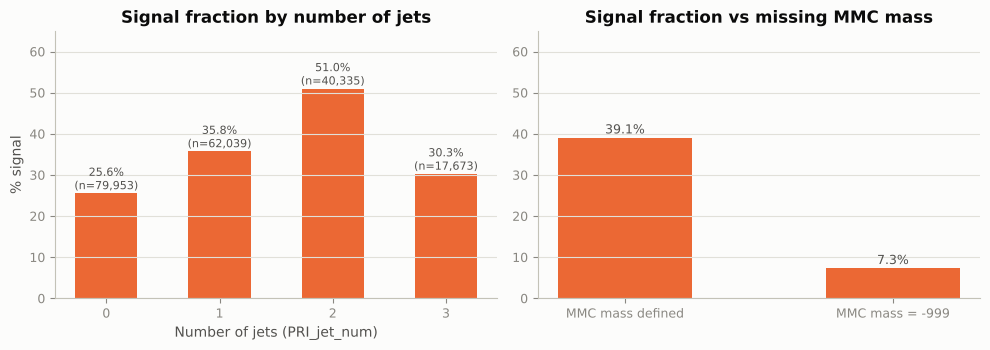

In [ ]:
y_tmp = (train[LABEL_COL] == "s").astype(int)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

jet = y_tmp.groupby(train["PRI_jet_num"]).agg(["mean", "size"])
axes[0].bar(jet.index.astype(str), 100 * jet["mean"], color=C_SIG, width=0.55)
for i, (m, n) in enumerate(zip(jet["mean"], jet["size"])):
    axes[0].text(i, 100 * m + 1, f"{100*m:.1f}%\n(n={n:,})", ha="center", color=INK2, fontsize=8)
axes[0].set_xlabel("Number of jets (PRI_jet_num)"); axes[0].set_ylabel("% signal")
axes[0].set_ylim(0, 65); axes[0].set_title("Signal fraction by number of jets")

mmc = y_tmp.groupby(train["DER_mass_MMC"] == -999.0).mean()
axes[1].bar(["MMC mass defined", "MMC mass = -999"], 100 * mmc.values, color=C_SIG, width=0.5)
for i, m in enumerate(mmc.values):
    axes[1].text(i, 100 * m + 1, f"{100*m:.1f}%", ha="center", color=INK2, fontsize=9)
axes[1].set_ylim(0, 65); axes[1].set_title("Signal fraction vs missing MMC mass")
for ax in axes: ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "05_signal_fraction_jets_mmc"); plt.show()

**Observation.** The number of jets is clearly related to the label: the signal fraction rises from **25.6%** with 0 jets to **51.0%** with 2 jets. This matches the physics: some Higgs bosons are produced by vector-boson fusion, which gives two forward jets.

Missing MMC mass is a very strong hint of background: only **7.3%** of those events are signal, compared with **39.1%** when the mass is defined. So I will keep an explicit "MMC missing" flag.

### 3.3 Feature distributions: signal vs background
Each panel compares the normalised distribution of one feature for the two classes (-999 values excluded, axes clipped to the 0.5–99.5 percentile range so the tails don't squash the plot).

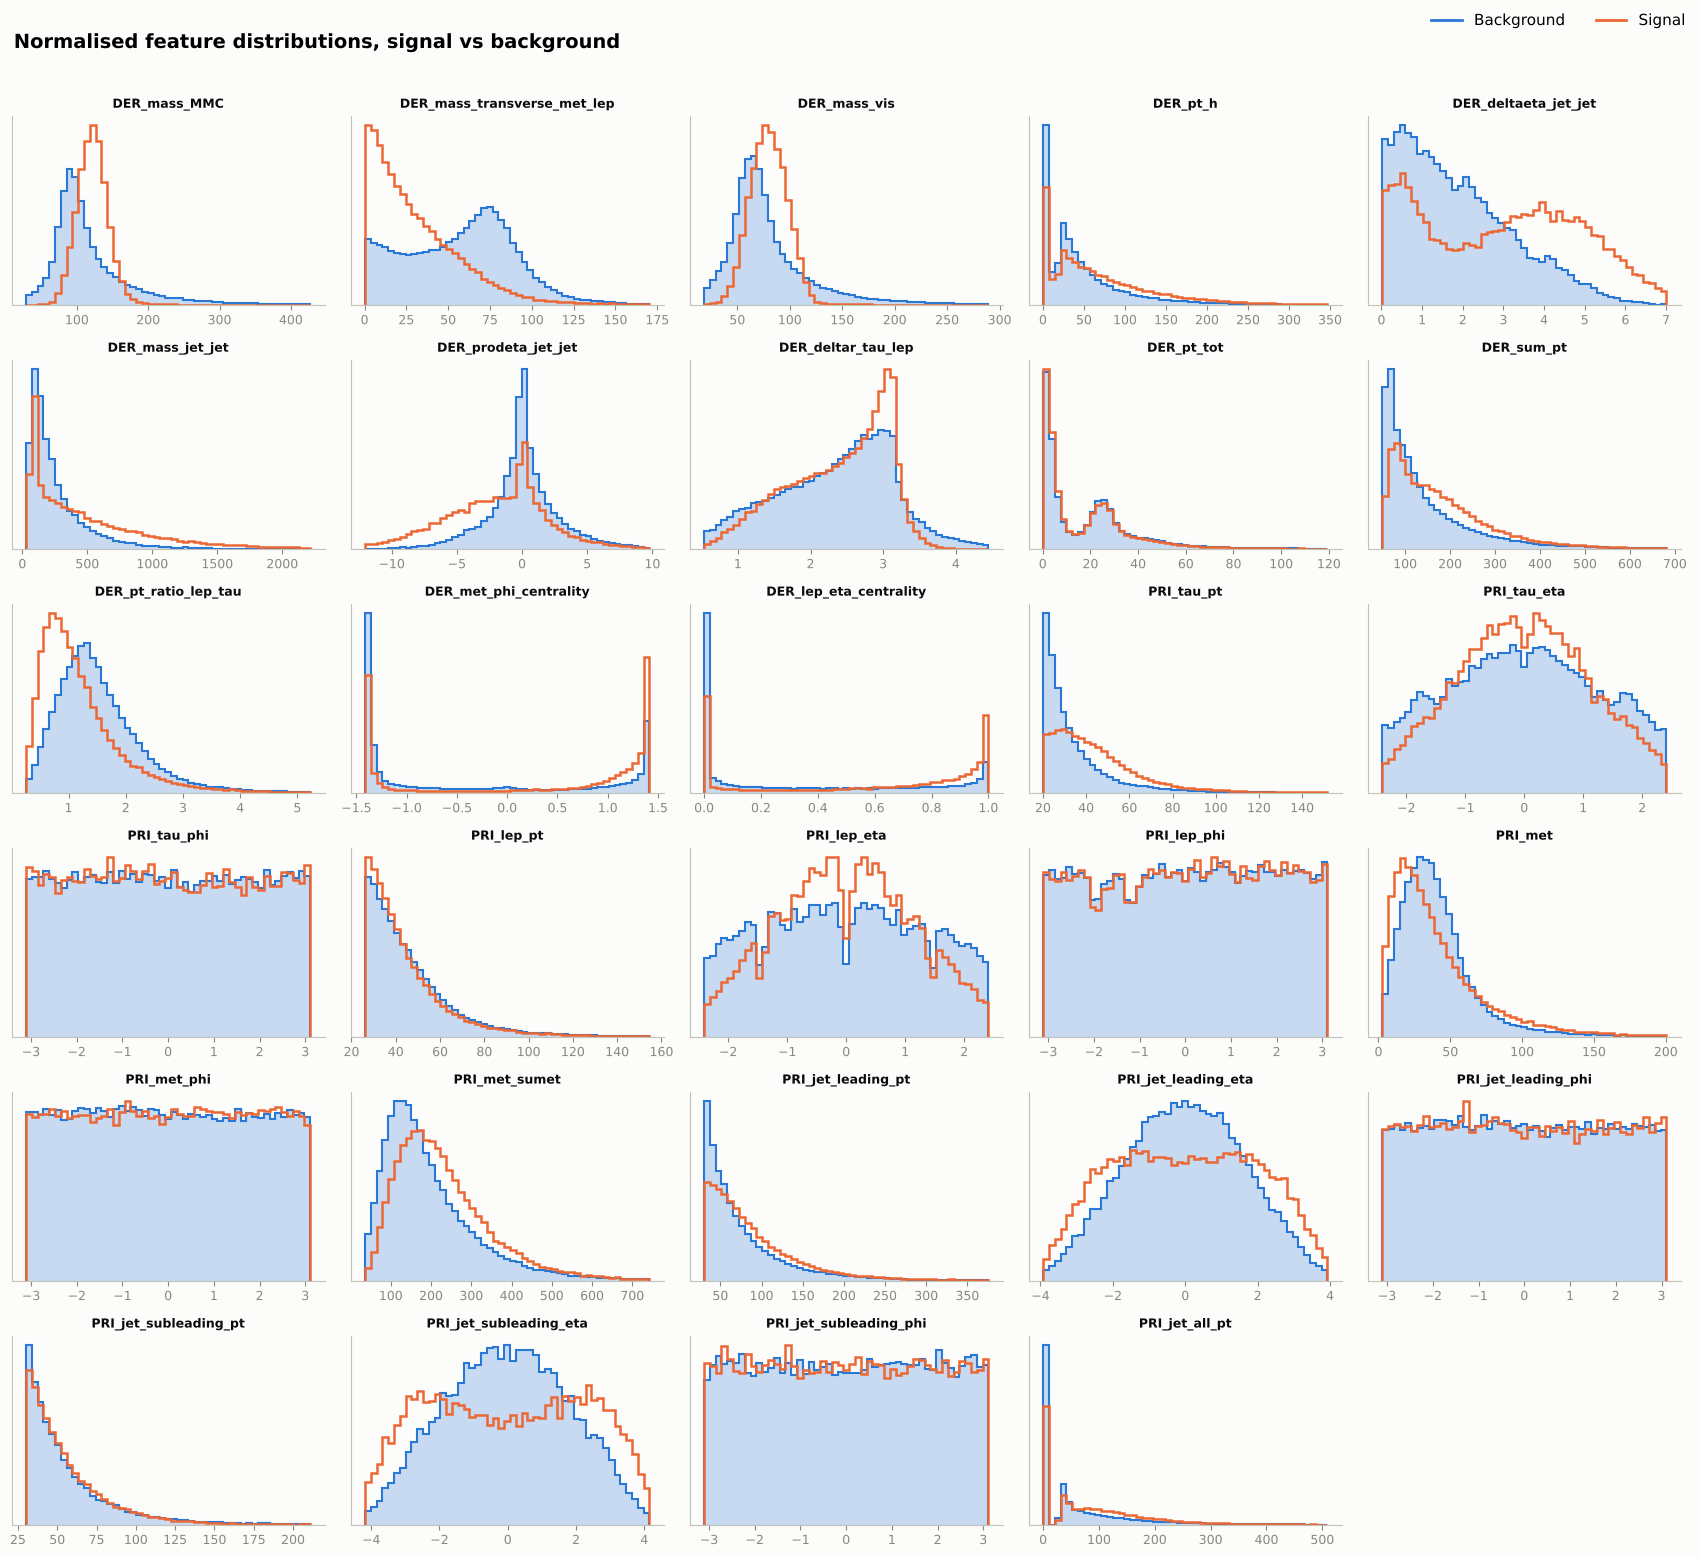

In [ ]:
cont = [c for c in FEATURES if c != "PRI_jet_num"]
ncol = 5; nrow = int(np.ceil(len(cont) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(17, 2.6 * nrow))
for ax, c in zip(axes.ravel(), cont):
    v = train.loc[train[c] != -999.0, [c, LABEL_COL]]
    lo, hi = v[c].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 50)
    ax.hist(v.loc[v[LABEL_COL] == "b", c], bins=bins, density=True, color=C_BKG,
            alpha=0.25, lw=0)
    ax.hist(v.loc[v[LABEL_COL] == "b", c], bins=bins, density=True, histtype="step", color=C_BKG, lw=1.5)
    ax.hist(v.loc[v[LABEL_COL] == "s", c], bins=bins, density=True, histtype="step", color=C_SIG, lw=1.8)
    ax.set_title(c, fontsize=9); ax.set_yticks([]); ax.grid(False)
for ax in axes.ravel()[len(cont):]: ax.axis("off")
fig.legend(handles=[plt.Line2D([], [], color=C_BKG, lw=2, label="Background"),
                    plt.Line2D([], [], color=C_SIG, lw=2, label="Signal")],
           loc="upper right", ncol=2, fontsize=11)
fig.suptitle("Normalised feature distributions, signal vs background", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97)); save(fig, "06_feature_distributions"); plt.show()

**Observations.**
* **`DER_mass_MMC`** and **`DER_mass_vis`**: signal peaks at higher mass than background (signal median 121 GeV vs 102 GeV for MMC). The signal peak sits near the Higgs mass of 125 GeV, while the background peak is closer to the Z boson mass (91 GeV), from Z → ττ events.
* **`DER_mass_transverse_met_lep`** is the clearest separator: signal piles up near 0 (median 24 GeV) while background has a broad bump around 60–80 GeV, typical of W → ℓν decays.
* **`DER_deltaeta_jet_jet`** and **`DER_prodeta_jet_jet`**: signal events have jets that are far apart in η with opposite signs, the vector-boson fusion signature mentioned above.
* **`DER_pt_ratio_lep_tau`** and **`PRI_tau_pt`**: also differ clearly.
* The five **`*_phi`** angles look flat and identical for signal and background. On their own they are useless (Section 4.1 explains why and what to do instead).
* Most momentum and energy features have long right tails (Section 3.6).

### 3.4 How much can each feature separate the classes on its own?
A quick way to rank features: compute the ROC-AUC obtained by using the raw value of one feature as the classifier score (only events where the feature is defined). An AUC of 0.5 means no information; I report max(AUC, 1−AUC) so the direction doesn't matter.

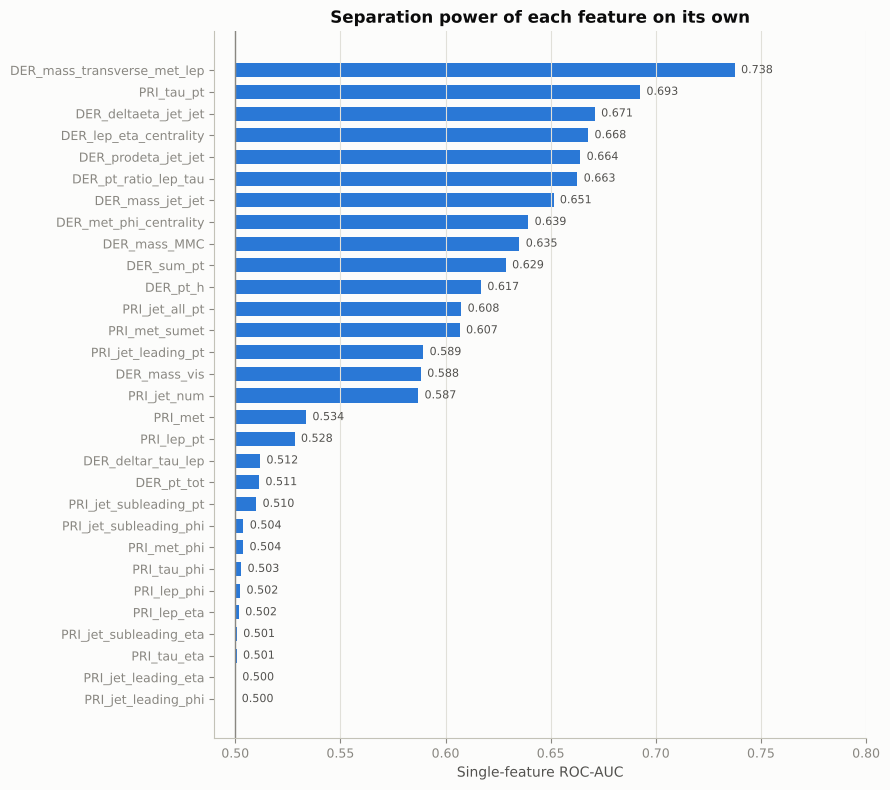

In [ ]:
rows = []
for c in FEATURES:
    m = train[c] != -999.0
    auc = roc_auc_score(y_tmp[m], train.loc[m, c])
    rows.append((c, max(auc, 1 - auc), m.mean()))
single_auc = pd.DataFrame(rows, columns=["feature", "auc", "defined_frac"]).sort_values("auc")

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(single_auc["feature"], single_auc["auc"] - 0.5, left=0.5, color=C_BKG, height=0.65)
for i, a in enumerate(single_auc["auc"]):
    ax.text(a + 0.003, i, f"{a:.3f}", va="center", fontsize=8, color=INK2)
ax.axvline(0.5, color=MUTED, lw=1)
ax.set_xlim(0.49, 0.80); ax.set_xlabel("Single-feature ROC-AUC")
ax.set_title("Separation power of each feature on its own"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "07_single_feature_auc"); plt.show()

**Observation.** The best single feature is `DER_mass_transverse_met_lep` (AUC **0.738**), followed by `PRI_tau_pt` (0.693) and the dijet features (≈0.66–0.67, computed only on the 29% of events with two jets). The raw φ and η angles sit at ≈0.50, meaning no information on their own.

One surprise: `DER_mass_MMC` only reaches **0.635**, even though its histogram looked very different between the classes. The next cell explains why.

AUC using raw DER_mass_MMC        : 0.635
AUC using |DER_mass_MMC - 125 GeV|: 0.773


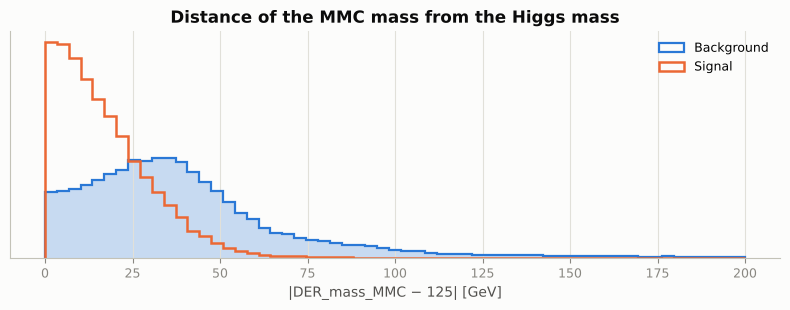

In [ ]:
# DER_mass_MMC looked very discriminating in the histograms, so why is its
# single-feature AUC only moderate? Because signal is not "higher" or "lower":
# it PEAKS near the Higgs mass. A threshold on the raw value cannot capture a peak,
# but the distance from 125 GeV can.
m = train["DER_mass_MMC"] != -999.0
mmc = train.loc[m, "DER_mass_MMC"]
a_raw  = roc_auc_score(y_tmp[m], mmc)
a_dist = roc_auc_score(y_tmp[m], -(mmc - 125).abs())
print(f"AUC using raw DER_mass_MMC        : {max(a_raw, 1 - a_raw):.3f}")
print(f"AUC using |DER_mass_MMC - 125 GeV|: {a_dist:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(0, 200, 60)
d = (mmc - 125).abs()
ax.hist(d[y_tmp[m] == 0], bins=bins, density=True, color=C_BKG, alpha=0.25, lw=0)
ax.hist(d[y_tmp[m] == 0], bins=bins, density=True, histtype="step", color=C_BKG, lw=1.6, label="Background")
ax.hist(d[y_tmp[m] == 1], bins=bins, density=True, histtype="step", color=C_SIG, lw=1.8, label="Signal")
ax.set_xlabel("|DER_mass_MMC − 125| [GeV]"); ax.set_yticks([]); ax.legend()
ax.set_title("Distance of the MMC mass from the Higgs mass")
fig.tight_layout(); save(fig, "07b_mmc_distance_from_125"); plt.show()

**Observation.** Using the *distance* from 125 GeV instead of the raw value raises the single-feature AUC from **0.635 to 0.773**, making it the strongest single feature of all. Signal is concentrated in a window around the Higgs mass, with background on both sides, so a single cut on the raw value cannot separate them.

Tree models can learn this window by themselves with two splits, but logistic regression is linear in its inputs and cannot. So I add `MMC_dist_125 = |DER_mass_MMC − 125|` as an engineered feature.

### 3.5 Correlations between features

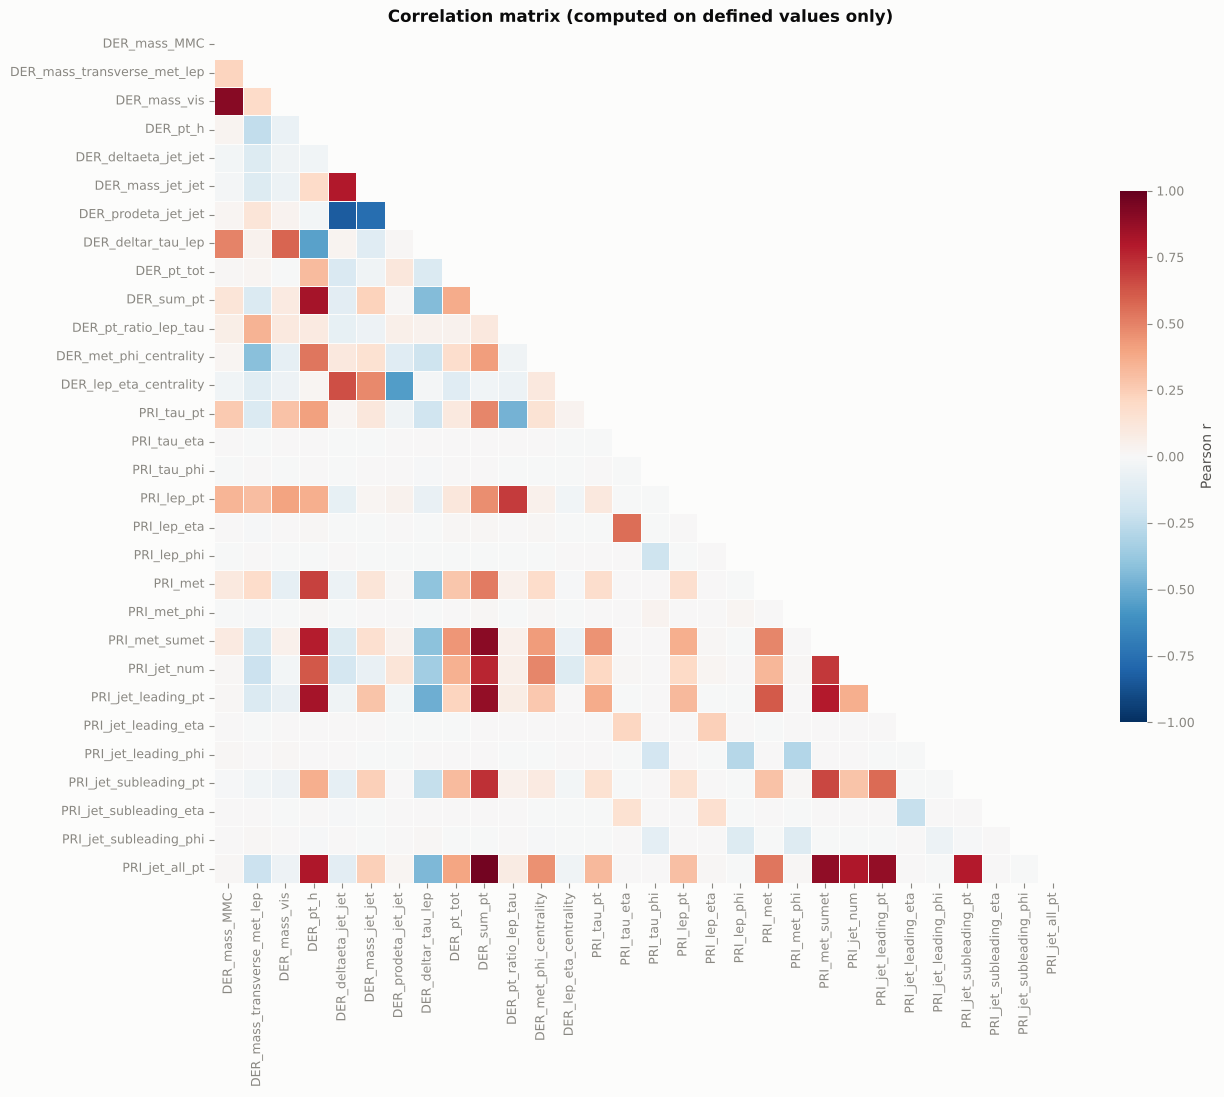

Most strongly correlated pairs (|r| > 0.8):
            level_0              level_1      r
     PRI_jet_all_pt           DER_sum_pt  0.965
       DER_mass_vis         DER_mass_MMC  0.911
      PRI_met_sumet           DER_sum_pt  0.904
     PRI_jet_all_pt        PRI_met_sumet  0.884
 PRI_jet_leading_pt           DER_sum_pt  0.879
     PRI_jet_all_pt   PRI_jet_leading_pt  0.879
DER_prodeta_jet_jet DER_deltaeta_jet_jet -0.836
         DER_sum_pt             DER_pt_h  0.834
 PRI_jet_leading_pt             DER_pt_h  0.829
     PRI_jet_all_pt             DER_pt_h  0.811
     PRI_jet_all_pt          PRI_jet_num  0.806


In [ ]:
corr = train[FEATURES].replace(-999.0, np.nan).corr()

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.4, linecolor=SURFACE, cbar_kws={"shrink": 0.6, "label": "Pearson r"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation matrix (computed on defined values only)")
fig.tight_layout(); save(fig, "08_correlation_matrix"); plt.show()

pairs = (corr.where(~mask).stack().rename("r").reset_index()
         .assign(abs_r=lambda d: d.r.abs()).sort_values("abs_r", ascending=False))
print("Most strongly correlated pairs (|r| > 0.8):")
print(pairs[pairs.abs_r > 0.8][["level_0", "level_1", "r"]].round(3).to_string(index=False))

**Observation.** There are several groups of strongly correlated features:
* `DER_sum_pt`, `PRI_jet_all_pt`, `PRI_met_sumet`, `PRI_jet_leading_pt` and `DER_pt_h` (r between 0.81 and 0.97): these are all sums or combinations of transverse momenta, so the correlation is expected.
* `DER_mass_vis` and `DER_mass_MMC` (r = 0.91): both estimate the mass of the ττ system.
* `DER_deltaeta_jet_jet` and `DER_prodeta_jet_jet` (r = −0.84).

Correlated features are not a problem for tree models. For logistic regression they make individual coefficients less interpretable but L2 regularisation keeps the fit stable, so I keep all features rather than dropping information.

### 3.6 Skewness of the features

,DER_pt_tot,PRI_met,PRI_tau_pt,DER_mass_MMC,DER_mass_vis,PRI_lep_pt,PRI_jet_subleading_pt,DER_pt_ratio_lep_tau,DER_pt_h,PRI_jet_leading_pt,...,PRI_tau_eta,PRI_jet_leading_phi,PRI_tau_phi,PRI_met_phi,PRI_jet_leading_eta,PRI_jet_subleading_phi,PRI_jet_subleading_eta,PRI_lep_phi,DER_deltar_tau_lep,DER_prodeta_jet_jet
skewness,12.41,5.83,3.83,3.82,3.74,3.23,3.17,2.63,2.62,2.55,...,0.02,0.02,0.01,0.01,0.0,-0.0,-0.0,-0.04,-0.22,-0.32


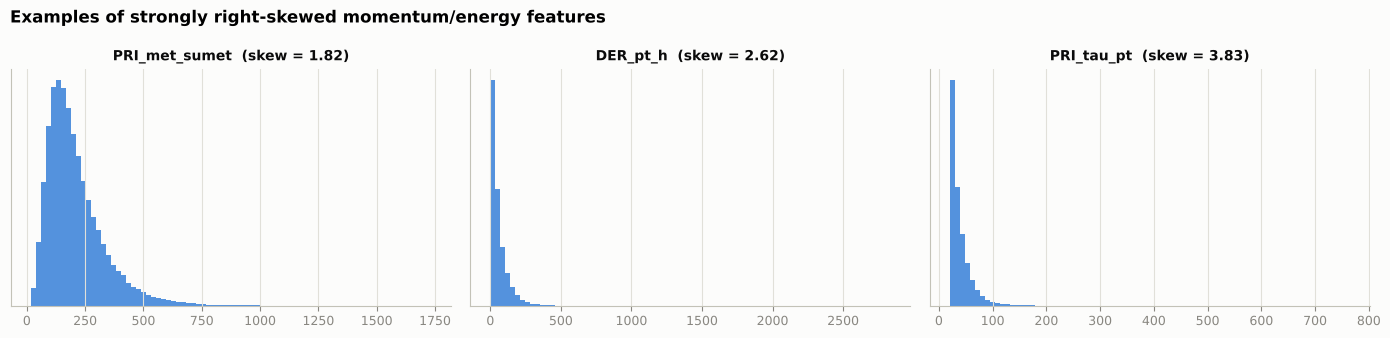

In [ ]:
skew = train[FEATURES].replace(-999.0, np.nan).skew().sort_values(ascending=False)
display(skew.to_frame("skewness").round(2).T)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, c in zip(axes, ["PRI_met_sumet", "DER_pt_h", "PRI_tau_pt"]):
    v = train.loc[train[c] != -999.0, c]
    ax.hist(v, bins=80, color=C_BKG, alpha=0.8)
    ax.set_title(f"{c}  (skew = {skew[c]:.2f})", fontsize=10); ax.set_yticks([])
fig.suptitle("Examples of strongly right-skewed momentum/energy features", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout(); save(fig, "09_skewed_examples"); plt.show()

**Observation.** Most energy and momentum features are strongly right-skewed (e.g. `DER_pt_tot` 12.4, `PRI_met` 5.8, `PRI_tau_pt` 3.8). For logistic regression a few extreme values would dominate the fit, so I apply a `log1p` transform to the non-negative skewed features. Angles and pseudorapidities are already symmetric (skew ≈ 0) and are left alone.

### 3.7 Two of the strongest features together

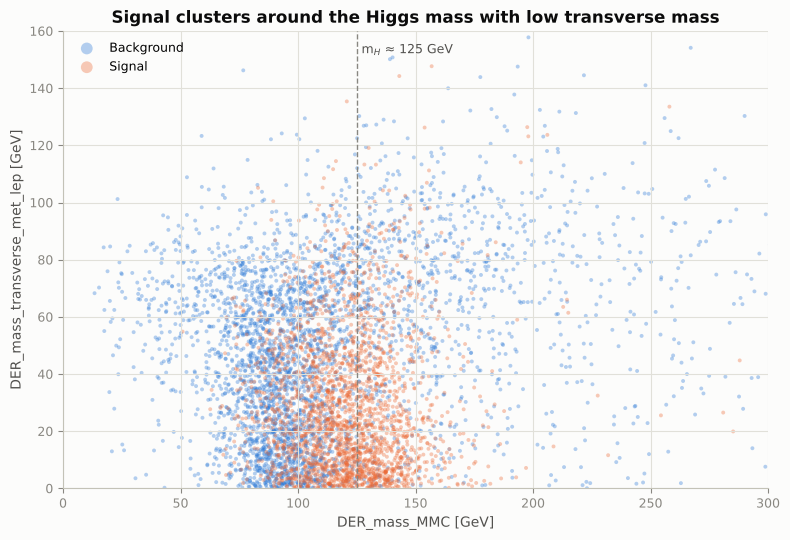

In [ ]:
sample = train[(train["DER_mass_MMC"] != -999.0)].sample(6000, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 5.5))
for lab, col, name in [("b", C_BKG, "Background"), ("s", C_SIG, "Signal")]:
    d = sample[sample[LABEL_COL] == lab]
    ax.scatter(d["DER_mass_MMC"], d["DER_mass_transverse_met_lep"], s=8, alpha=0.35,
               color=col, label=name, edgecolors="none")
ax.set_xlim(0, 300); ax.set_ylim(0, 160)
ax.axvline(125, color=MUTED, lw=1, ls="--"); ax.text(127, 152, "m$_H$ ≈ 125 GeV", color=INK2, fontsize=9)
ax.set_xlabel("DER_mass_MMC [GeV]"); ax.set_ylabel("DER_mass_transverse_met_lep [GeV]")
ax.set_title("Signal clusters around the Higgs mass with low transverse mass")
ax.legend(markerscale=3)
fig.tight_layout(); save(fig, "10_mmc_vs_mt_scatter"); plt.show()

**Observation.** In two dimensions the separation is much clearer than in either feature alone: signal forms a dense cluster at MMC mass ≈ 100–150 GeV and low transverse mass, while background spreads over a much wider region. Even so, the two classes overlap substantially, so no simple pair of cuts would separate them. This is the motivation for multivariate machine-learning models.

### EDA summary: what this means for preprocessing

| Finding | Decision |
|---|---|
| `-999` marks undefined values, mostly caused by having 0 or 1 jets | Convert to `NaN`. Trees can use NaN directly; for logistic regression impute with the median and keep the jet count as one-hot columns so the model knows *why* a value is missing |
| `DER_mass_MMC` is missing in some events and those events are mostly background | Add an explicit missing-indicator column |
| Raw $\phi$ angles have flat, identical distributions | Replace them with angle *differences* $\Delta\phi$ between objects, which are physically meaningful |
| Signal *peaks* near 125 GeV in `DER_mass_MMC`, which a linear model cannot capture | Add a new feature $|m_{MMC} - 125|$ |
| Energy/momentum features are heavily right-skewed | Apply `log1p` before scaling for logistic regression |
| Signal weights are much smaller than background weights | Train with class-balanced weights, evaluate the physics metric with the original weights |
| Several features are strongly correlated | Keep them for the tree models; L2 regularisation handles it for logistic regression |

## 4. Data preprocessing and feature engineering

Every statistic used here (medians, means, standard deviations, the list of skewed columns) is **computed on the training data only** and then applied unchanged to the validation and test data. The test set is not touched until Section 6.

### 4.1 Angle features: from $\phi$ to $\Delta\phi$
The detector is symmetric around the beam axis, so the absolute azimuthal angle $\phi$ of a particle carries no information: rotating the whole event changes every $\phi$ but not the physics. What matters is the **angle between objects**. I replace the five raw $\phi$ columns with four differences, wrapped to $[0, \pi]$:

$$\Delta\phi(a,b) = \min\big(|\phi_a-\phi_b|,\; 2\pi-|\phi_a-\phi_b|\big)$$

The same function also adds the `MMC_dist_125` feature motivated in Section 3.4.

In [ ]:
PHI_COLS = ["PRI_tau_phi", "PRI_lep_phi", "PRI_met_phi",
            "PRI_jet_leading_phi", "PRI_jet_subleading_phi"]

def delta_phi(a, b):
    d = np.abs(a - b)
    return np.where(d > np.pi, 2 * np.pi - d, d)   # NaN stays NaN

def build_features(df):
    # Turn a raw dataframe into (features X, label y, physics weight w).
    X = df[FEATURES].replace(-999.0, np.nan).copy()
    X["DPHI_tau_lep"]  = delta_phi(X["PRI_tau_phi"], X["PRI_lep_phi"])
    X["DPHI_tau_met"]  = delta_phi(X["PRI_tau_phi"], X["PRI_met_phi"])
    X["DPHI_lep_met"]  = delta_phi(X["PRI_lep_phi"], X["PRI_met_phi"])
    X["DPHI_tau_jet1"] = delta_phi(X["PRI_tau_phi"], X["PRI_jet_leading_phi"])
    X = X.drop(columns=PHI_COLS)
    # distance of the MMC mass estimate from the Higgs mass (see Section 3.4)
    X["MMC_dist_125"] = (X["DER_mass_MMC"] - 125.0).abs()
    y = (df[LABEL_COL] == "s").astype(int).values
    w = df[WEIGHT_COL].astype(float).values
    return X, y, w

X_all, y_all, w_all = build_features(train)
print("Feature matrix:", X_all.shape)
print("NaN fraction after replacing -999:", round(X_all.isna().mean().mean(), 3))

Feature matrix: (200000, 30)
NaN fraction after replacing -999: 0.192


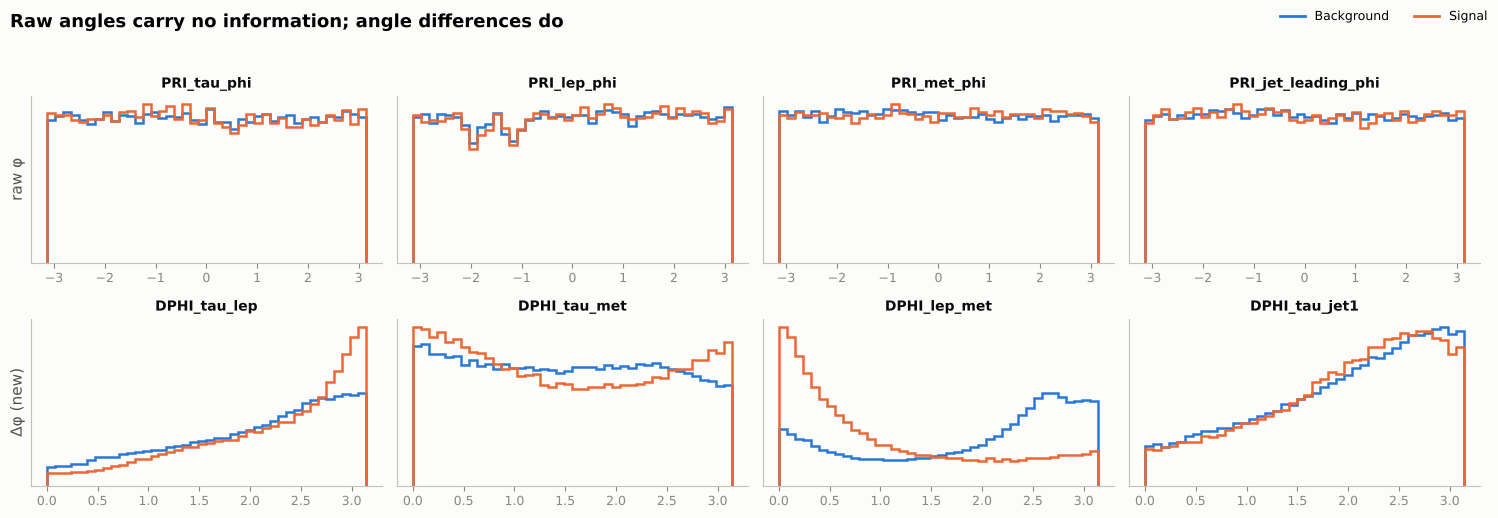

DPHI_tau_lep    single-feature AUC = 0.569
DPHI_tau_met    single-feature AUC = 0.504
DPHI_lep_met    single-feature AUC = 0.718
DPHI_tau_jet1   single-feature AUC = 0.501


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5.2))
raw = ["PRI_tau_phi", "PRI_lep_phi", "PRI_met_phi", "PRI_jet_leading_phi"]
new = ["DPHI_tau_lep", "DPHI_tau_met", "DPHI_lep_met", "DPHI_tau_jet1"]
for row, (cols, src) in enumerate([(raw, train[raw].replace(-999.0, np.nan)), (new, X_all[new])]):
    for ax, c in zip(axes[row], cols):
        for cls, col in [(0, C_BKG), (1, C_SIG)]:
            ax.hist(src.loc[y_all == cls, c].dropna(), bins=40, density=True,
                    histtype="step", color=col, lw=1.8)
        ax.set_title(c, fontsize=10); ax.set_yticks([]); ax.grid(False)
axes[0, 0].set_ylabel("raw φ", fontsize=11); axes[1, 0].set_ylabel("Δφ (new)", fontsize=11)
fig.legend(handles=[plt.Line2D([], [], color=C_BKG, lw=2, label="Background"),
                    plt.Line2D([], [], color=C_SIG, lw=2, label="Signal")],
           loc="upper right", ncol=2)
fig.suptitle("Raw angles carry no information; angle differences do", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95)); save(fig, "11_phi_vs_deltaphi"); plt.show()

for c in new:
    m = X_all[c].notna()
    a = roc_auc_score(y_all[m], X_all.loc[m, c])
    print(f"{c:<15} single-feature AUC = {max(a, 1-a):.3f}")

**Observation.** As expected, the raw φ histograms are flat for both classes, while the Δφ histograms are clearly different. `DPHI_lep_met` (angle between the lepton and the missing energy) reaches a single-feature AUC of **0.718**, almost as good as the best original feature, and `DPHI_tau_lep` reaches 0.569. `DPHI_tau_met` and `DPHI_tau_jet1` are close to 0.50 on their own, but may still help in combination with other features. Five useless columns have been replaced by four, and one of them is among the strongest features.

### 4.2 Train / validation split
I keep 15% of the training data aside as a **validation set**. It is used for choosing hyperparameters, for early stopping of the boosted trees, and for choosing the decision threshold for the AMS metric. This way the test set stays completely unseen until the final comparison.

In [ ]:
X_tr, X_val, y_tr, y_val, w_tr, w_val = train_test_split(
    X_all, y_all, w_all, test_size=0.15, stratify=y_all, random_state=SEED)

print(f"Train      : {len(X_tr):>7,} events, signal fraction {y_tr.mean():.4f}")
print(f"Validation : {len(X_val):>7,} events, signal fraction {y_val.mean():.4f}")

Train      : 170,000 events, signal fraction 0.3427
Validation :  30,000 events, signal fraction 0.3427


### 4.3 Training weights
If I trained with the raw physics weights, every signal event would count roughly a thousand times less than a background event and the models would learn to ignore signal. The usual approach in the HiggsML challenge is to **rescale the weights so that both classes have the same total weight**, while keeping the relative weights *inside* each class. The original weights are kept separately for the AMS metric.

In [ ]:
def balanced_weights(y, w):
    # Rescale so each class has total weight N/2; mean weight is 1.
    out = w.astype(float).copy()
    for cls in (0, 1):
        m = y == cls
        out[m] = out[m] / out[m].sum() * (len(y) / 2)
    return out

sw_tr  = balanced_weights(y_tr, w_tr)
sw_val = balanced_weights(y_val, w_val)

print("Sum of training weights per class:")
print(f"  before: background = {w_tr[y_tr==0].sum():,.1f}   signal = {w_tr[y_tr==1].sum():,.1f}")
print(f"  after : background = {sw_tr[y_tr==0].sum():,.1f}   signal = {sw_tr[y_tr==1].sum():,.1f}")

Sum of training weights per class:
  before: background = 279,758.3   signal = 470.2
  after : background = 85,000.0   signal = 85,000.0


### 4.4 Preprocessing pipeline for logistic regression
Tree-based models (Random Forest, XGBoost, LightGBM) don't care about feature scale or skewness and can handle `NaN` natively (scikit-learn's Random Forest supports missing values since version 1.4), so they get the feature matrix as is.

Logistic regression is a linear model and needs more care. I wrote a small preprocessor class with `fit` / `transform`, so that everything is learned on the training split only:

1. `log1p` on non-negative features with skewness > 1
2. one-hot encode `PRI_jet_num` (the effect of jet count is not linear)
3. a missing indicator for `DER_mass_MMC`
4. median imputation of remaining `NaN` (these are always explained by the jet count columns)
5. standardisation to zero mean and unit variance

In [ ]:
class LinearPreprocessor:
    def fit(self, X):
        Xn = X.drop(columns=["PRI_jet_num"])
        sk = Xn.skew()
        self.log_cols = [c for c in Xn.columns if Xn[c].min() >= 0 and sk[c] > 1]
        Xn = self._log(Xn)
        self.medians = Xn.median()
        Z = self._assemble(X, Xn.fillna(self.medians))
        self.mean, self.std = Z.mean(), Z.std().replace(0, 1)
        self.columns = Z.columns
        return self

    def _log(self, Xn):
        Xn = Xn.copy()
        Xn[self.log_cols] = np.log1p(Xn[self.log_cols])
        return Xn

    @staticmethod
    def _assemble(X, Xn_filled):
        jets = pd.get_dummies(X["PRI_jet_num"].astype(int), prefix="jets").reindex(
            columns=[f"jets_{k}" for k in range(4)], fill_value=0).astype(float)
        mmc_missing = X["DER_mass_MMC"].isna().astype(float).rename("MMC_missing")
        return pd.concat([Xn_filled, jets, mmc_missing], axis=1)

    def transform(self, X):
        Xn = self._log(X.drop(columns=["PRI_jet_num"])).fillna(self.medians)
        Z = self._assemble(X, Xn)[self.columns]
        return (Z - self.mean) / self.std

lin_prep = LinearPreprocessor().fit(X_tr)
Xl_tr, Xl_val = lin_prep.transform(X_tr), lin_prep.transform(X_val)

print(f"log1p applied to {len(lin_prep.log_cols)} columns:")
print(", ".join(lin_prep.log_cols))
print("\nLinear-model feature matrix:", Xl_tr.shape)
print("Any NaN left:", Xl_tr.isna().any().any())

log1p applied to 16 columns:
DER_mass_MMC, DER_mass_transverse_met_lep, DER_mass_vis, DER_pt_h, DER_mass_jet_jet, DER_pt_tot, DER_sum_pt, DER_pt_ratio_lep_tau, PRI_tau_pt, PRI_lep_pt, PRI_met, PRI_met_sumet, PRI_jet_leading_pt, PRI_jet_subleading_pt, PRI_jet_all_pt, MMC_dist_125

Linear-model feature matrix: (170000, 34)
Any NaN left: False


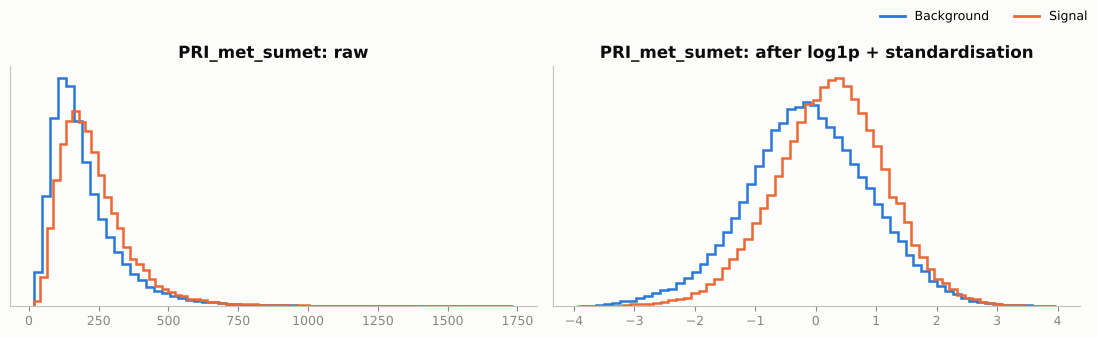

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
c = "PRI_met_sumet"
for cls, col in [(0, C_BKG), (1, C_SIG)]:
    axes[0].hist(X_tr.loc[y_tr == cls, c], bins=60, density=True, histtype="step", color=col, lw=1.8)
    axes[1].hist(Xl_tr.loc[y_tr == cls, c], bins=60, density=True, histtype="step", color=col, lw=1.8)
axes[0].set_title(f"{c}: raw"); axes[1].set_title(f"{c}: after log1p + standardisation")
for ax in axes: ax.set_yticks([]); ax.grid(False)
fig.legend(handles=[plt.Line2D([], [], color=C_BKG, lw=2, label="Background"),
                    plt.Line2D([], [], color=C_SIG, lw=2, label="Signal")], loc="upper right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.92)); save(fig, "12_log_transform_effect"); plt.show()

## 5. Model training
All four models are trained on the same 85% training split with the same class-balanced weights. Hyperparameters are chosen using the validation set.

In [ ]:
models, train_time, val_scores = {}, {}, {}

### 5.1 Logistic Regression
A linear baseline: it models $P(\text{signal}\mid x) = \sigma(w^\top x + b)$. The main hyperparameter is the inverse regularisation strength $C$ (smaller $C$ means stronger L2 penalty), which I scan on the validation set.

C =    0.001   validation AUC = 0.8374


C =    0.010   validation AUC = 0.8395


C =    0.100   validation AUC = 0.8401


C =    1.000   validation AUC = 0.8400


C =   10.000   validation AUC = 0.8400


C =  100.000   validation AUC = 0.8400


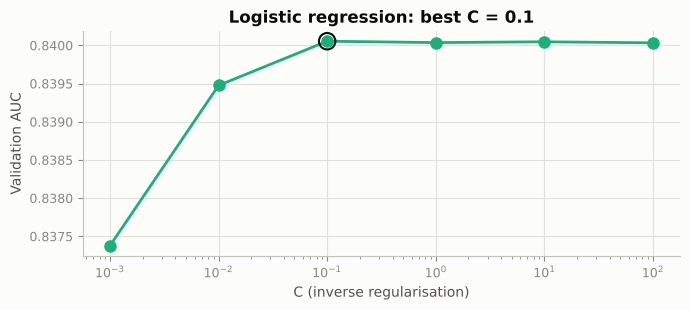

In [ ]:
C_grid = np.logspace(-3, 2, 6)
lr_auc = []
for C in C_grid:
    m = LogisticRegression(C=C, max_iter=2000, solver="lbfgs")
    m.fit(Xl_tr, y_tr, sample_weight=sw_tr)
    lr_auc.append(roc_auc_score(y_val, m.predict_proba(Xl_val)[:, 1]))
    print(f"C = {C:>8.3f}   validation AUC = {lr_auc[-1]:.4f}")

best_C = C_grid[int(np.argmax(lr_auc))]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(C_grid, lr_auc, marker="o", ms=8, color=MODEL_COLORS["Logistic Regression"])
ax.scatter([best_C], [max(lr_auc)], s=140, facecolors="none", edgecolors=INK, lw=1.5, zorder=3)
ax.set_xscale("log"); ax.set_xlabel("C (inverse regularisation)"); ax.set_ylabel("Validation AUC")
ax.set_title(f"Logistic regression: best C = {best_C:g}")
fig.tight_layout(); save(fig, "13_lr_C_scan"); plt.show()

In [ ]:
t0 = time.time()
lr_model = LogisticRegression(C=best_C, max_iter=2000, solver="lbfgs")
lr_model.fit(Xl_tr, y_tr, sample_weight=sw_tr)
train_time["Logistic Regression"] = time.time() - t0
models["Logistic Regression"] = lr_model
val_scores["Logistic Regression"] = lr_model.predict_proba(Xl_val)[:, 1]
print(f"Trained in {train_time['Logistic Regression']:.1f} s, "
      f"validation AUC = {roc_auc_score(y_val, val_scores['Logistic Regression']):.4f}")

Trained in 0.7 s, validation AUC = 0.8401


### 5.2 Random Forest
An ensemble of decision trees, each grown on a bootstrap sample with a random subset of features at every split; the final score is the average vote. I limit tree depth and require at least 5 events per leaf to avoid memorising the training data, and check the out-of-bag (OOB) score as a free internal estimate.

In [ ]:
t0 = time.time()
rf_model = RandomForestClassifier(n_estimators=300, max_depth=18, min_samples_leaf=5,
                                  max_features="sqrt", oob_score=True,
                                  n_jobs=-1, random_state=SEED)
rf_model.fit(X_tr, y_tr, sample_weight=sw_tr)
train_time["Random Forest"] = time.time() - t0
models["Random Forest"] = rf_model
val_scores["Random Forest"] = rf_model.predict_proba(X_val)[:, 1]
print(f"Trained in {train_time['Random Forest']:.1f} s")
print(f"OOB accuracy        = {rf_model.oob_score_:.4f}")
print(f"Validation AUC      = {roc_auc_score(y_val, val_scores['Random Forest']):.4f}")
print(f"Training AUC        = {roc_auc_score(y_tr, rf_model.predict_proba(X_tr)[:, 1]):.4f}  (gap shows overfitting)")

Trained in 107.5 s
OOB accuracy        = 0.8040
Validation AUC      = 0.8982


Training AUC        = 0.9450  (gap shows overfitting)


### 5.3 XGBoost
Gradient boosting builds trees one after another, each one fitting the errors of the ensemble so far. XGBoost adds regularisation on leaf weights and learns a default direction for missing values at every split, which suits the `NaN` structure of this data. I use early stopping on the validation AUC to choose the number of trees.

In [ ]:
t0 = time.time()
xgb_model = xgb.XGBClassifier(
    n_estimators=3000, learning_rate=0.05, max_depth=6, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    tree_method="hist", eval_metric=["logloss", "auc"], early_stopping_rounds=100,
    n_jobs=-1, random_state=SEED)
xgb_model.fit(X_tr, y_tr, sample_weight=sw_tr,
              eval_set=[(X_tr, y_tr), (X_val, y_val)],
              sample_weight_eval_set=[sw_tr, sw_val], verbose=False)
train_time["XGBoost"] = time.time() - t0
models["XGBoost"] = xgb_model
val_scores["XGBoost"] = xgb_model.predict_proba(X_val)[:, 1]
print(f"Trained in {train_time['XGBoost']:.1f} s, best iteration = {xgb_model.best_iteration}")
print(f"Validation AUC = {roc_auc_score(y_val, val_scores['XGBoost']):.4f}")

Trained in 17.0 s, best iteration = 287
Validation AUC = 0.9028


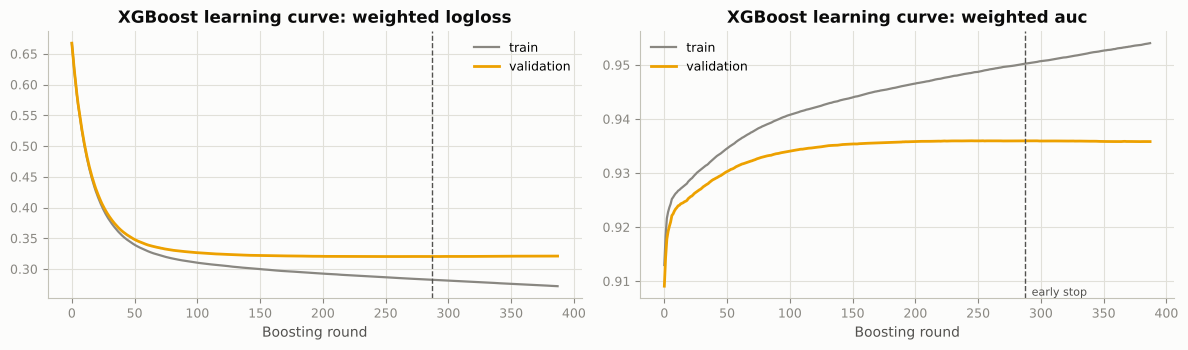

In [ ]:
ev = xgb_model.evals_result()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, metric in zip(axes, ["logloss", "auc"]):
    ax.plot(ev["validation_0"][metric], color=MUTED, lw=1.6, label="train")
    ax.plot(ev["validation_1"][metric], color=MODEL_COLORS["XGBoost"], lw=2, label="validation")
    ax.axvline(xgb_model.best_iteration, color=INK2, ls="--", lw=1)
    ax.set_xlabel("Boosting round"); ax.set_title(f"XGBoost learning curve: weighted {metric}")
    ax.legend()
axes[1].text(xgb_model.best_iteration, axes[1].get_ylim()[0], "  early stop", color=INK2,
             fontsize=8, va="bottom")
fig.tight_layout(); save(fig, "14_xgb_learning_curve"); plt.show()

### 5.4 LightGBM
LightGBM is another gradient-boosting library. It grows trees **leaf-wise** (always splitting the leaf with the largest loss reduction) and bins features into histograms, which makes it fast. Its main capacity parameter is `num_leaves`, so I scan it with early stopping on the validation set.

num_leaves =  15   best iteration =  554   validation AUC = 0.9015


num_leaves =  31   best iteration =  340   validation AUC = 0.9017


num_leaves =  63   best iteration =  194   validation AUC = 0.9016


num_leaves = 127   best iteration =  136   validation AUC = 0.9017


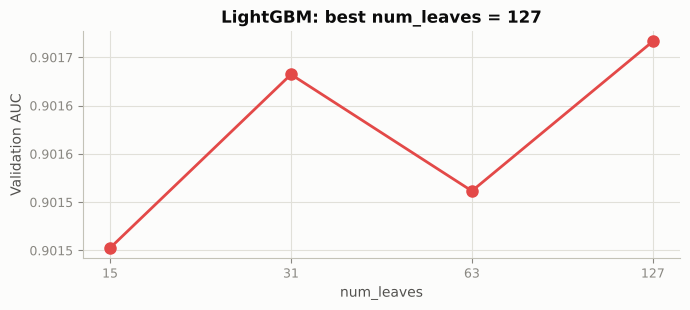

In [ ]:
def fit_lgbm(num_leaves, record=None):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, num_leaves=num_leaves,
                           min_child_samples=40, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, reg_lambda=1.0,
                           n_jobs=-1, random_state=SEED, verbose=-1)
    cbs = [lgb.early_stopping(100, verbose=False)]
    if record is not None:
        cbs.append(lgb.record_evaluation(record))
    m.fit(X_tr, y_tr, sample_weight=sw_tr,
          eval_set=[(X_tr, y_tr), (X_val, y_val)], eval_sample_weight=[sw_tr, sw_val],
          eval_names=["train", "validation"], eval_metric=["binary_logloss", "auc"], callbacks=cbs)
    return m

leaves_grid, leaves_auc, leaves_iter = [15, 31, 63, 127], [], []
for nl in leaves_grid:
    m = fit_lgbm(nl)
    leaves_auc.append(roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]))
    leaves_iter.append(m.best_iteration_)
    print(f"num_leaves = {nl:>3}   best iteration = {m.best_iteration_:>4}   validation AUC = {leaves_auc[-1]:.4f}")
best_leaves = leaves_grid[int(np.argmax(leaves_auc))]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot([str(n) for n in leaves_grid], leaves_auc, marker="o", ms=8, color=MODEL_COLORS["LightGBM"])
ax.set_xlabel("num_leaves"); ax.set_ylabel("Validation AUC")
ax.set_title(f"LightGBM: best num_leaves = {best_leaves}")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.4f"))
fig.tight_layout(); save(fig, "15_lgbm_leaves_scan"); plt.show()

Trained in 10.7 s, best iteration = 136
Validation AUC = 0.9017


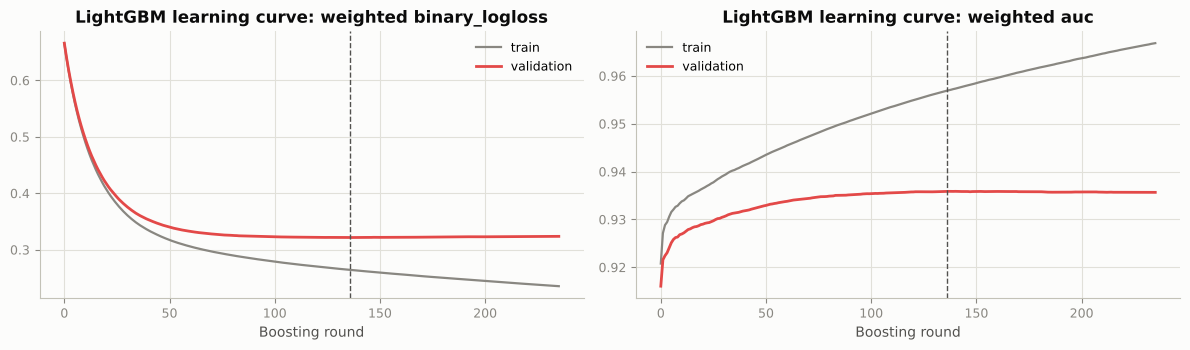

In [ ]:
lgb_hist = {}
t0 = time.time()
lgb_model = fit_lgbm(best_leaves, record=lgb_hist)
train_time["LightGBM"] = time.time() - t0
models["LightGBM"] = lgb_model
val_scores["LightGBM"] = lgb_model.predict_proba(X_val)[:, 1]
print(f"Trained in {train_time['LightGBM']:.1f} s, best iteration = {lgb_model.best_iteration_}")
print(f"Validation AUC = {roc_auc_score(y_val, val_scores['LightGBM']):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, metric in zip(axes, ["binary_logloss", "auc"]):
    ax.plot(lgb_hist["train"][metric], color=MUTED, lw=1.6, label="train")
    ax.plot(lgb_hist["validation"][metric], color=MODEL_COLORS["LightGBM"], lw=2, label="validation")
    ax.axvline(lgb_model.best_iteration_, color=INK2, ls="--", lw=1)
    ax.set_xlabel("Boosting round"); ax.set_title(f"LightGBM learning curve: weighted {metric}")
    ax.legend()
fig.tight_layout(); save(fig, "16_lgbm_learning_curve"); plt.show()

## 6. Evaluation on the test set
Now, for the first time, I load `../testing_data/test.csv`. It goes through exactly the same `build_features` function and the **already fitted** logistic-regression preprocessor.

**Metrics**
* **Accuracy, precision, recall, F1** at threshold 0.5 (the models were trained with balanced weights, so 0.5 is a natural default).
* **ROC-AUC**: threshold-independent ranking quality; the main ML metric.
* **Weighted ROC-AUC**: ROC-AUC with the physics weights, as recommended by the dataset author.
* **PR-AUC** (average precision) and **log loss**.
* **AMS (Approximate Median Significance)**: the physics metric used in the HiggsML challenge. If $s$ and $b$ are the weighted numbers of signal and background events that pass a selection, then

$$\text{AMS} = \sqrt{2\left[(s+b+b_r)\ln\!\left(1+\frac{s}{b+b_r}\right)-s\right]},\qquad b_r = 10$$

  which approximates the statistical significance (in σ) of a discovery. The threshold that maximises AMS is chosen **on the validation set** and then applied to the test set. Because a subset only contains part of the events, its weights are scaled up by $N_{\text{total}}/N_{\text{subset}}$.

In [ ]:
test = pd.read_csv(TEST_PATH)
X_te, y_te, w_te = build_features(test)
Xl_te = lin_prep.transform(X_te)
print("Test set:", X_te.shape, f" signal fraction {y_te.mean():.4f}")

def predict(name, X, Xl):
    return models[name].predict_proba(Xl if name == "Logistic Regression" else X)[:, 1]

test_scores = {name: predict(name, X_te, Xl_te) for name in models}

Test set: (50000, 30)  signal fraction 0.3427


In [ ]:
def ams(s, b, br=10.0):
    return np.sqrt(2 * ((s + b + br) * np.log(1 + s / (b + br)) - s))

def ams_curve(y, p, w, thresholds):
    w = w * N_TOTAL / len(y)                    # rescale weights to the full dataset
    out = []
    for t in thresholds:
        sel = p >= t
        out.append(ams(w[sel & (y == 1)].sum(), w[sel & (y == 0)].sum()))
    return np.array(out)

THRESH = np.linspace(0.5, 0.995, 200)
ams_thr, ams_val_curves, ams_test_curves = {}, {}, {}
for name in models:
    ams_val_curves[name]  = ams_curve(y_val, val_scores[name], w_val, THRESH)
    ams_test_curves[name] = ams_curve(y_te, test_scores[name], w_te, THRESH)
    ams_thr[name] = THRESH[np.argmax(ams_val_curves[name])]
    print(f"{name:<20} AMS-optimal threshold (from validation) = {ams_thr[name]:.3f}")

Logistic Regression  AMS-optimal threshold (from validation) = 0.833
Random Forest        AMS-optimal threshold (from validation) = 0.925


XGBoost              AMS-optimal threshold (from validation) = 0.933
LightGBM             AMS-optimal threshold (from validation) = 0.960


In [ ]:
rows = []
for name, p in test_scores.items():
    pred = (p >= 0.5).astype(int)
    sel = p >= ams_thr[name]
    w_scaled = w_te * N_TOTAL / len(y_te)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "ROC-AUC": roc_auc_score(y_te, p),
        "Weighted ROC-AUC": roc_auc_score(y_te, p, sample_weight=w_te),
        "PR-AUC": average_precision_score(y_te, p),
        "Log loss": log_loss(y_te, p),
        "AMS": ams(w_scaled[sel & (y_te == 1)].sum(), w_scaled[sel & (y_te == 0)].sum()),
        "Train time (s)": train_time[name],
    })
results = pd.DataFrame(rows).set_index("Model")
results.to_csv(os.path.join(RESULT_DIR, "test_metrics.csv"))

higher_better = [c for c in results.columns if c not in ("Log loss", "Train time (s)")]
(results.style.format("{:.4f}").format("{:.1f}", subset=["Train time (s)"])
        .highlight_max(subset=higher_better, color="#cde2fb")
        .highlight_min(subset=["Log loss"], color="#cde2fb"))

,Accuracy,Precision,Recall,F1,ROC-AUC,Weighted ROC-AUC,PR-AUC,Log loss,AMS,Train time (s)
Model,,,,,,,,,,
Logistic Regression,0.7281,0.5690,0.8522,0.6823,0.8355,0.9051,0.7105,0.5848,2.4607,0.7
Random Forest,0.8043,0.6708,0.8422,0.7468,0.8951,0.9313,0.8223,0.4190,3.3732,107.5
XGBoost,0.7948,0.6489,0.8740,0.7448,0.9002,0.9346,0.8336,0.4399,3.6299,17.0
LightGBM,0.7955,0.6511,0.8691,0.7445,0.8988,0.9343,0.8306,0.4391,3.2673,10.7


### 6.1 ROC and precision–recall curves

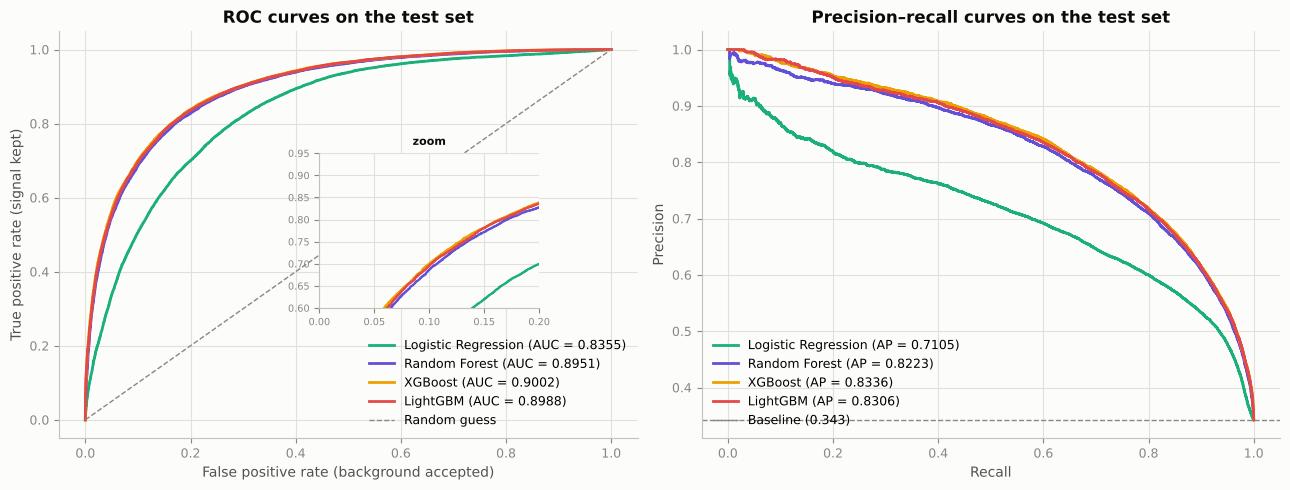

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in test_scores.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], label=f"{name} (AUC = {results.loc[name,'ROC-AUC']:.4f})")
    prec, rec, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], label=f"{name} (AP = {results.loc[name,'PR-AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="Random guess")
axes[0].set_xlabel("False positive rate (background accepted)"); axes[0].set_ylabel("True positive rate (signal kept)")
axes[0].set_title("ROC curves on the test set"); axes[0].legend(loc="lower right")
axes[1].axhline(y_te.mean(), color=MUTED, lw=1, ls="--", label=f"Baseline ({y_te.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curves on the test set"); axes[1].legend(loc="lower left")

# zoomed inset of the ROC region where the models differ
ins = axes[0].inset_axes([0.45, 0.32, 0.38, 0.38])
for name, p in test_scores.items():
    fpr, tpr, _ = roc_curve(y_te, p); ins.plot(fpr, tpr, color=MODEL_COLORS[name], lw=1.6)
ins.set_xlim(0.0, 0.2); ins.set_ylim(0.6, 0.95); ins.tick_params(labelsize=7); ins.set_title("zoom", fontsize=8)
fig.tight_layout(); save(fig, "17_roc_pr_curves"); plt.show()

**Observations.**
* The three tree-based models are almost on top of each other: ROC-AUC **0.900** (XGBoost), **0.899** (LightGBM) and **0.895** (Random Forest). The zoomed inset shows that Random Forest is slightly below the two boosting models in the low false-positive region, which is the region that matters most for physics, where we want to keep background very low.
* Logistic regression is clearly behind at **0.836**. That is still a reasonable baseline, and it is a large improvement over the **0.803** validation AUC it reached in my first run *without* the `MMC_dist_125` feature. The gap to the trees shows the decision boundary is strongly non-linear.
* The precision–recall curves tell the same story: at 50% recall the boosted trees keep about 87% precision, logistic regression only about 73%.

### 6.2 Confusion matrices (threshold 0.5)

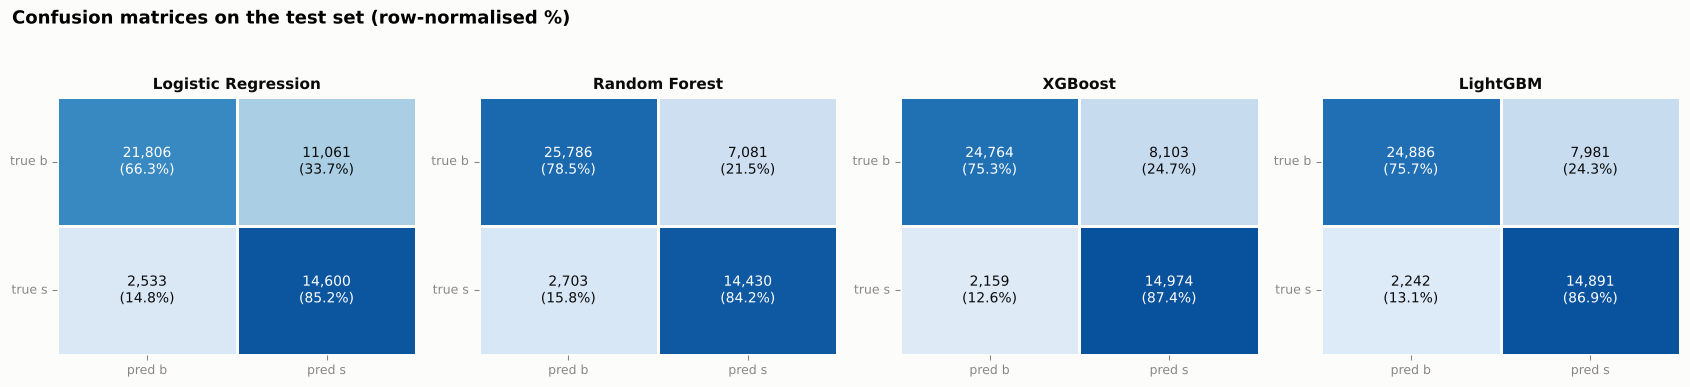

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
for ax, (name, p) in zip(axes, test_scores.items()):
    cm = confusion_matrix(y_te, (p >= 0.5).astype(int))
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_pct, annot=False, cmap="Blues", vmin=0, vmax=1, cbar=False,
                linewidths=2, linecolor=SURFACE, ax=ax)
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j + 0.5, i + 0.5, f"{cm[i, j]:,}\n({100*cm_pct[i, j]:.1f}%)", ha="center", va="center",
                    color="white" if cm_pct[i, j] > 0.5 else INK, fontsize=10)
    ax.set_xticklabels(["pred b", "pred s"]); ax.set_yticklabels(["true b", "true s"], rotation=0)
    ax.set_title(name, fontsize=11)
fig.suptitle("Confusion matrices on the test set (row-normalised %)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93)); save(fig, "18_confusion_matrices"); plt.show()

### 6.3 Score distributions
A good classifier pushes background towards 0 and signal towards 1. The overlap region is where the mistakes happen.

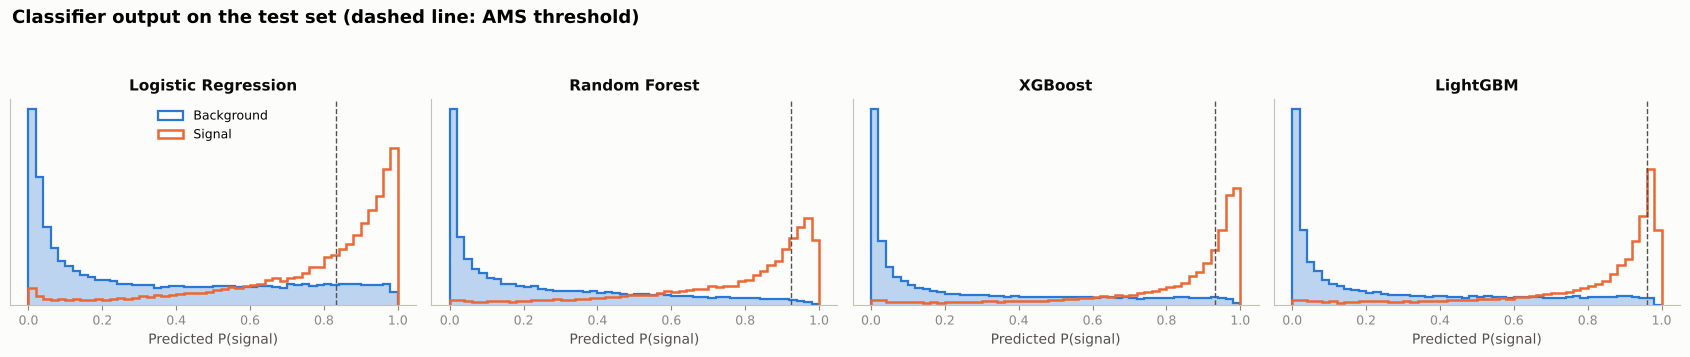

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=False)
bins = np.linspace(0, 1, 51)
for ax, (name, p) in zip(axes, test_scores.items()):
    ax.hist(p[y_te == 0], bins=bins, density=True, color=C_BKG, alpha=0.3, lw=0)
    ax.hist(p[y_te == 0], bins=bins, density=True, histtype="step", color=C_BKG, lw=1.6, label="Background")
    ax.hist(p[y_te == 1], bins=bins, density=True, histtype="step", color=C_SIG, lw=1.8, label="Signal")
    ax.axvline(ams_thr[name], color=INK2, ls="--", lw=1)
    ax.set_title(name, fontsize=11); ax.set_xlabel("Predicted P(signal)"); ax.set_yticks([]); ax.grid(False)
axes[0].legend(loc="upper center")
fig.suptitle("Classifier output on the test set (dashed line: AMS threshold)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92)); save(fig, "19_score_distributions"); plt.show()

### 6.4 Physics metric: AMS vs decision threshold

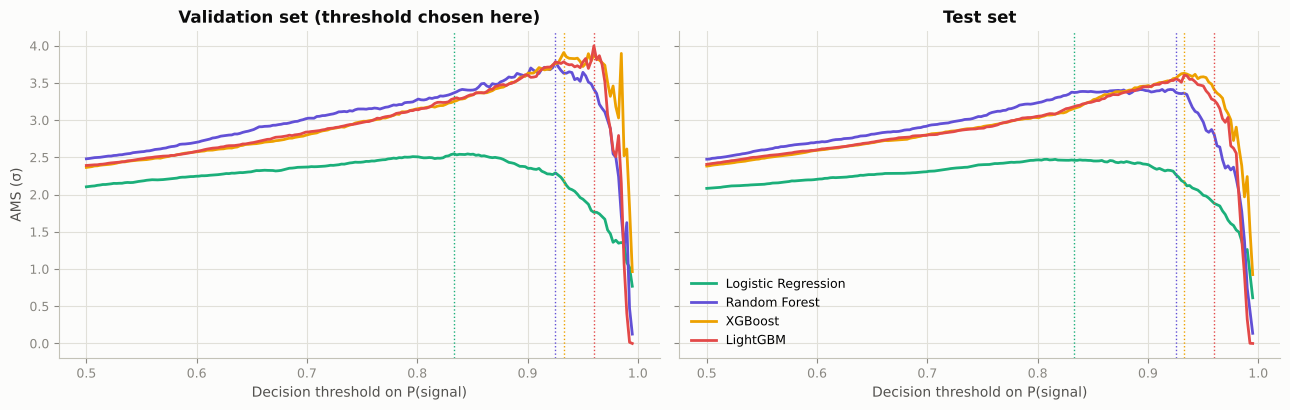

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, curves, title in [(axes[0], ams_val_curves, "Validation set (threshold chosen here)"),
                          (axes[1], ams_test_curves, "Test set")]:
    for name, curve in curves.items():
        ax.plot(THRESH, curve, color=MODEL_COLORS[name], label=name)
        ax.axvline(ams_thr[name], color=MODEL_COLORS[name], ls=":", lw=1)
    ax.set_xlabel("Decision threshold on P(signal)"); ax.set_title(title)
axes[0].set_ylabel("AMS (σ)"); axes[1].legend(loc="lower left")
fig.tight_layout(); save(fig, "20_ams_vs_threshold"); plt.show()

**Observations.**
* For every tree model, AMS keeps rising as the threshold increases and peaks at around **0.92–0.95**. The best selection keeps only events the classifier is very confident about: a small but very pure signal region gives the highest significance.
* Logistic regression peaks much lower (≈2.5σ) because its high-score region is less pure.
* The validation curves are **noisy** above 0.9 (a few heavily weighted background events entering or leaving the selection cause jumps). LightGBM's threshold (0.96) was picked at one of these spikes. On the test set that threshold lands just past LightGBM's peak, which is why its test AMS (**3.27**) is lower than XGBoost's (**3.63**) even though their ROC curves are nearly identical. With only 30,000 validation events the AMS differences between the three tree models are within this noise, so I would not claim one is clearly better than another on AMS alone.

### 6.5 Side-by-side metric comparison

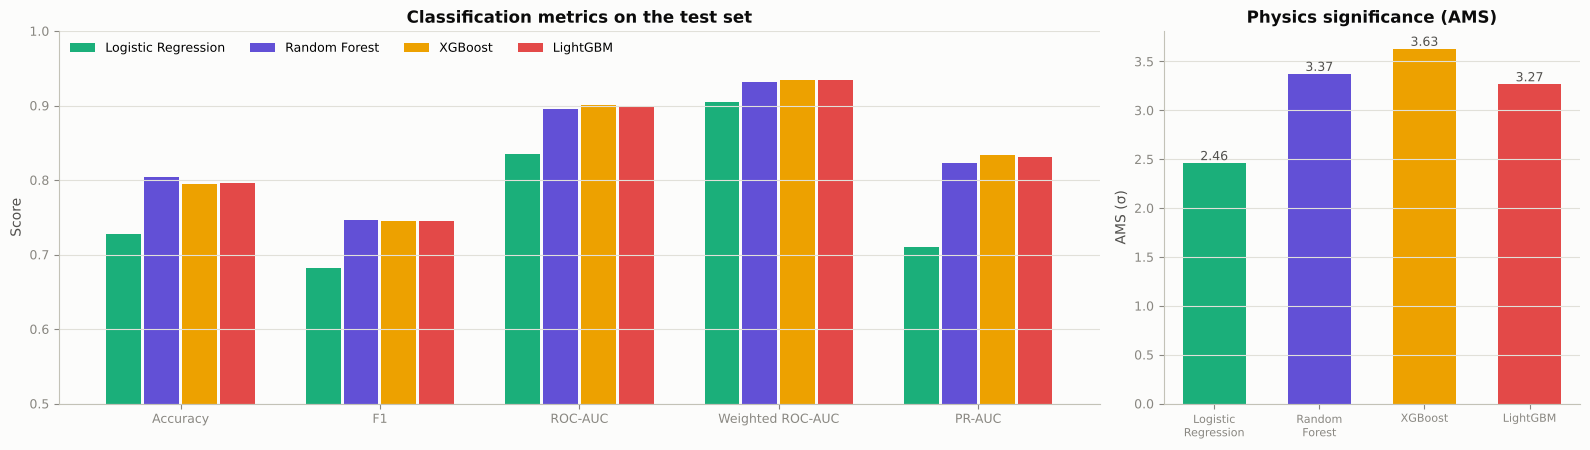

In [ ]:
show = ["Accuracy", "F1", "ROC-AUC", "Weighted ROC-AUC", "PR-AUC"]
names = list(results.index)
x = np.arange(len(show)); width = 0.19

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [3, 1.2]})
for i, name in enumerate(names):
    vals = results.loc[name, show].values
    axes[0].bar(x + (i - 1.5) * width, vals, width * 0.92, color=MODEL_COLORS[name], label=name)
axes[0].set_xticks(x); axes[0].set_xticklabels(show)
axes[0].set_ylim(0.5, 1.0); axes[0].set_ylabel("Score")
axes[0].set_title("Classification metrics on the test set"); axes[0].legend(ncol=4, loc="upper left")
axes[0].grid(axis="x", visible=False)

bars = axes[1].bar(range(len(names)), results["AMS"], color=[MODEL_COLORS[n] for n in names], width=0.6)
for b, v in zip(bars, results["AMS"]):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.2f}", ha="center", color=INK2, fontsize=9)
axes[1].set_xticks(range(len(names))); axes[1].set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=8)
axes[1].set_ylabel("AMS (σ)"); axes[1].set_title("Physics significance (AMS)")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "21_metric_comparison"); plt.show()

### 6.6 What did the models learn? Feature importance

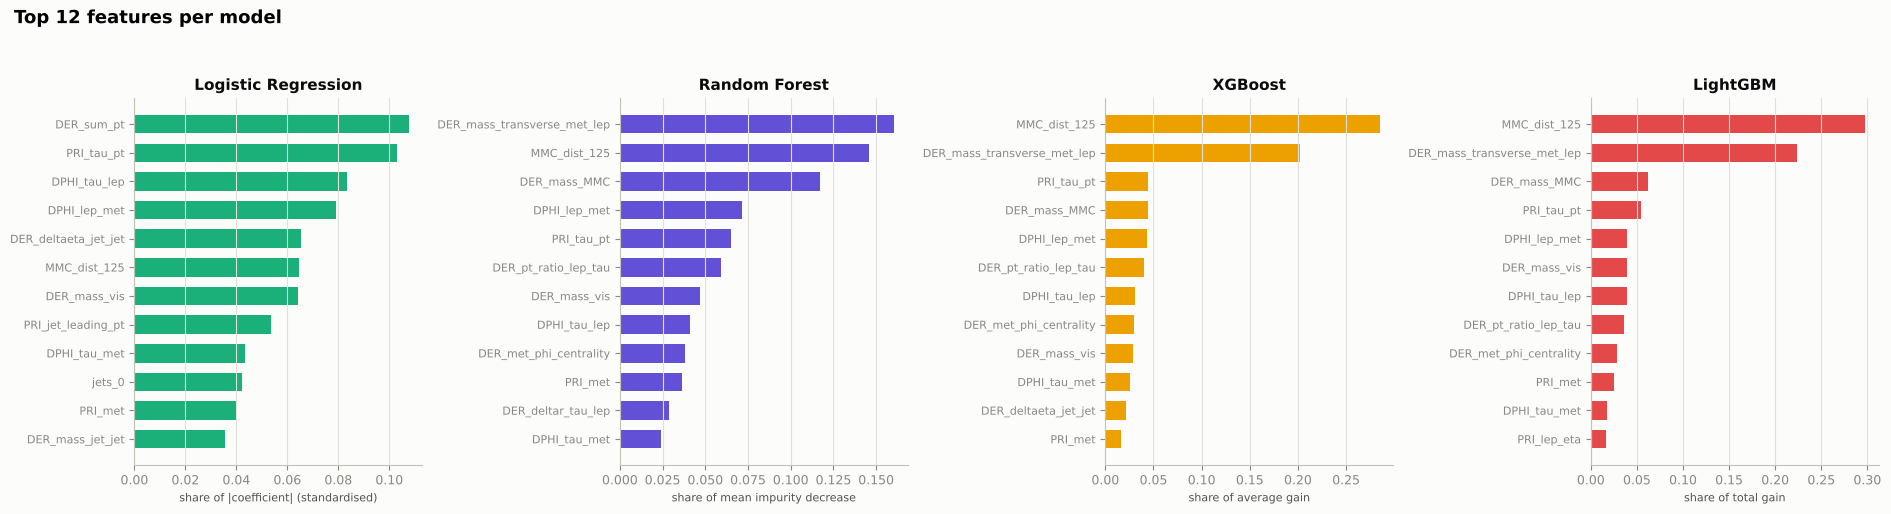

In [ ]:
imp = {
    "Logistic Regression": pd.Series(np.abs(lr_model.coef_[0]), index=lin_prep.columns),
    "Random Forest": pd.Series(rf_model.feature_importances_, index=X_tr.columns),
    "XGBoost": pd.Series(xgb_model.get_booster().get_score(importance_type="gain")).reindex(X_tr.columns).fillna(0),
    "LightGBM": pd.Series(lgb_model.booster_.feature_importance(importance_type="gain"), index=X_tr.columns),
}
labels = {"Logistic Regression": "|coefficient| (standardised)", "Random Forest": "mean impurity decrease",
          "XGBoost": "average gain", "LightGBM": "total gain"}

fig, axes = plt.subplots(1, 4, figsize=(19, 5.2))
for ax, (name, s) in zip(axes, imp.items()):
    top = (s / s.sum()).sort_values().tail(12)
    ax.barh(top.index, top.values, color=MODEL_COLORS[name], height=0.65)
    ax.set_title(name, fontsize=11); ax.set_xlabel(f"share of {labels[name]}", fontsize=8)
    ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
fig.suptitle("Top 12 features per model", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94)); save(fig, "22_feature_importance"); plt.show()

**Observations.**
* All three tree models agree on the two most important features: **`MMC_dist_125`** (the distance of the reconstructed mass from 125 GeV, ranked first by XGBoost and LightGBM and second by Random Forest) and **`DER_mass_transverse_met_lep`**. Then come `DER_mass_MMC`, `PRI_tau_pt`, `DER_mass_vis` and the Δφ features. This matches the EDA (Sections 3.3–3.4), so the models are using physically sensible information rather than an artefact.
* Two of my engineered features are therefore among the most useful: `MMC_dist_125` and **`DPHI_lep_met`**, which is in every model's top 6. `DPHI_tau_lep` and `DPHI_tau_met` also appear in every top 12, which confirms that replacing raw φ angles with angle differences was worthwhile.
* Logistic regression's ranking (based on standardised coefficients) looks different: it puts `DER_sum_pt` and `PRI_tau_pt` first, then the Δφ features. Coefficients of correlated features (Section 3.5) can trade off against each other, so its ranking is less reliable as a measure of importance.
* `Weight` and `EventId` were never inputs, so none of the importance comes from leakage.

### 6.7 Training cost

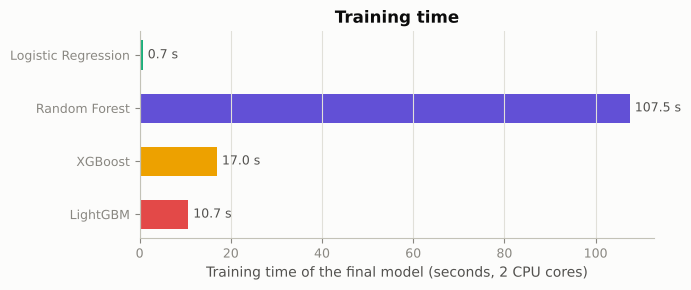

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
tt = results["Train time (s)"]
ax.barh(tt.index[::-1], tt.values[::-1], color=[MODEL_COLORS[n] for n in tt.index[::-1]], height=0.55)
for i, v in enumerate(tt.values[::-1]):
    ax.text(v + tt.max() * 0.01, i, f"{v:.1f} s", va="center", color=INK2, fontsize=9)
ax.set_xlabel("Training time of the final model (seconds, 2 CPU cores)")
ax.set_title("Training time"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "23_training_time"); plt.show()